In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Find project root
cwd = Path.cwd()

if (cwd / "data").is_dir() and (cwd / "outputs").is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data").is_dir() and (cwd.parent / "outputs").is_dir():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Cannot find the HAALSI_Project data/ and outputs/ folders."
    )

DATA = PROJECT_ROOT / "data"
OUTPUTS = PROJECT_ROOT / "outputs"

FIGURES = PROJECT_ROOT / "figures" / "supervisor"
FIGURES.mkdir(parents=True, exist_ok=True)

# Load datasets from data/ and results from outputs/
def load_csv(prefix):
    for folder in [DATA, OUTPUTS]:
        matches = sorted(
            folder.glob(f"{prefix}*.csv"),
            key=lambda p: p.stat().st_mtime,
            reverse=True
        )

        if matches:
            df = pd.read_csv(matches[0])
            print(
                f"Loaded [{folder.name}]: {matches[0].name} "
                f"({df.shape[0]:,} rows × {df.shape[1]} columns)"
            )
            return df

    print(f"Not found: {prefix}")
    return None


def get_col(df, *names):
    if df is None:
        return None

    lookup = {str(c).lower(): c for c in df.columns}

    for name in names:
        if name.lower() in lookup:
            return lookup[name.lower()]

    return None


def save_figure(name):
    plt.tight_layout()
    plt.savefig(
        FIGURES / f"{name}.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()


print("Project root:", PROJECT_ROOT)
print("Datasets in data/:", len(list(DATA.glob("*.csv"))))
print("Results in outputs/:", len(list(OUTPUTS.glob("*.csv"))))

Project root: c:\Users\kwane\Downloads\HAALSI_Project
Datasets in data/: 3
Results in outputs/: 95


In [2]:
longitudinal = load_csv("HAALSI_Longitudinal_SPC_Dataset")
narrowed = load_csv("HAALSI_Narrowed_SPC_Dataset")
paired = load_csv("HAALSI_Paired_Delayed_Recall_Analysis")

spc_changes = load_csv("section3_1_paired_spc_changes")
education_changes = load_csv("section3_1_spc_change_by_education")

Loaded [data]: HAALSI_Longitudinal_SPC_Dataset.csv (805 rows × 65 columns)
Loaded [data]: HAALSI_Narrowed_SPC_Dataset.csv (1,318 rows × 33 columns)
Loaded [data]: HAALSI_Paired_Delayed_Recall_Analysis.csv (504 rows × 65 columns)
Loaded [outputs]: section3_1_paired_spc_changes.csv (505 rows × 12 columns)
Loaded [outputs]: section3_1_spc_change_by_education.csv (6 rows × 10 columns)


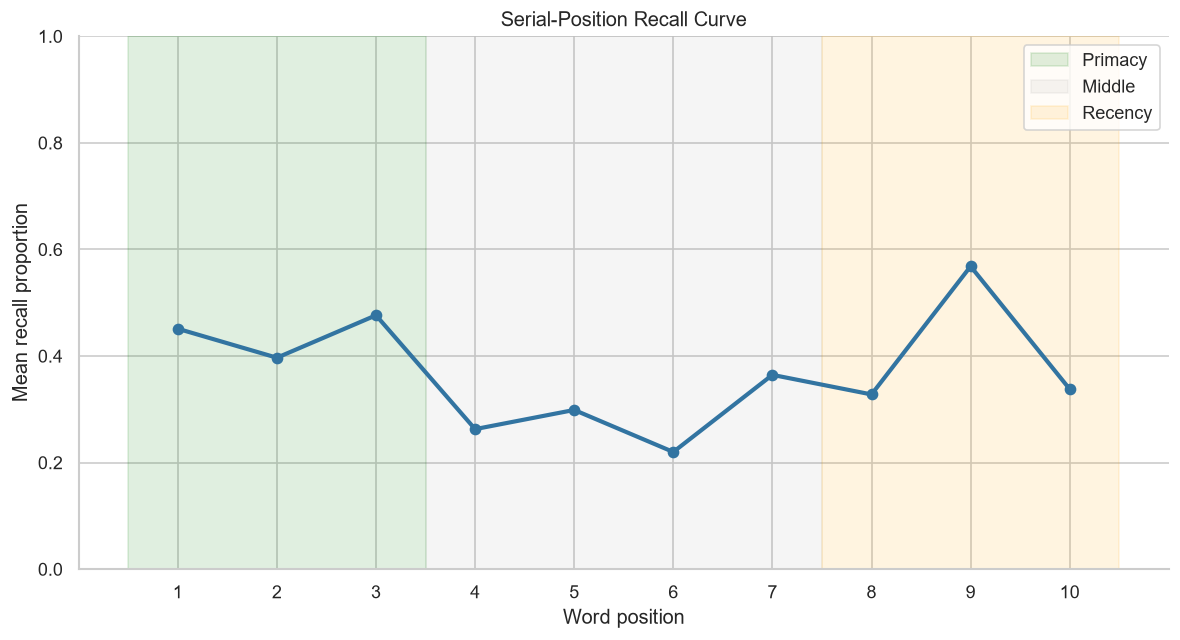

In [3]:
df = narrowed if narrowed is not None else longitudinal

word_cols = [
    get_col(df, f"trial_word_{i}", f"word_{i}")
    for i in range(1, 11)
]

if all(col is not None for col in word_cols):
    recall = df[word_cols].apply(pd.to_numeric, errors="coerce")
    position_means = recall.mean(axis=0)

    fig, ax = plt.subplots(figsize=(10, 5.5))

    ax.plot(
        range(1, 11),
        position_means.values,
        marker="o",
        linewidth=2.5,
        color="#3274A1"
    )

    ax.axvspan(0.5, 3.5, alpha=0.12, color="green", label="Primacy")
    ax.axvspan(3.5, 7.5, alpha=0.08, color="gray", label="Middle")
    ax.axvspan(7.5, 10.5, alpha=0.12, color="orange", label="Recency")

    ax.set_title("Serial-Position Recall Curve")
    ax.set_xlabel("Word position")
    ax.set_ylabel("Mean recall proportion")
    ax.set_xticks(range(1, 11))
    ax.set_ylim(0, 1)
    ax.legend()

    save_figure("05_serial_position_curve")
else:
    print("Word-position columns not found:")
    print(df.columns.tolist())

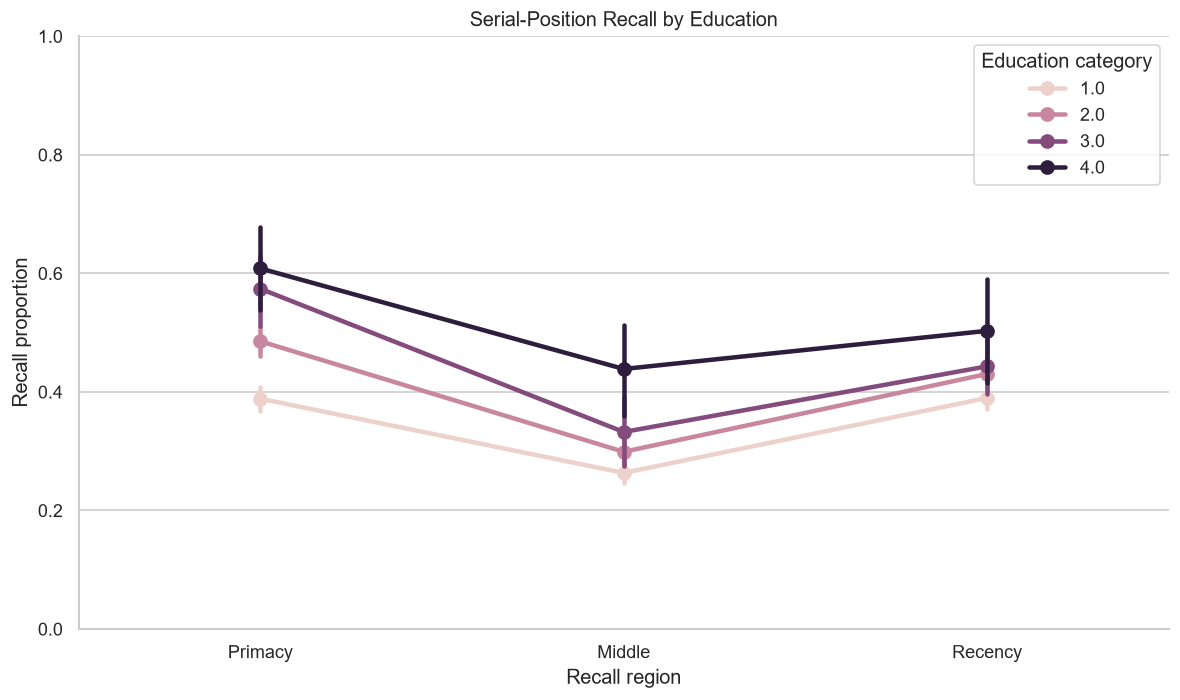

In [4]:
education_col = get_col(df, "education_level", "education")

region_cols = {
    "Primacy": get_col(df, "primacy_rate"),
    "Middle": get_col(df, "middle_rate"),
    "Recency": get_col(df, "recency_rate"),
}

if education_col and all(region_cols.values()):
    plot_df = df[
        [education_col] + list(region_cols.values())
    ].copy()

    plot_df = plot_df.rename(
        columns={v: k for k, v in region_cols.items()}
    )

    long_df = plot_df.melt(
        id_vars=education_col,
        value_vars=["Primacy", "Middle", "Recency"],
        var_name="Recall region",
        value_name="Recall proportion"
    )

    fig, ax = plt.subplots(figsize=(10, 6))

    sns.pointplot(
        data=long_df,
        x="Recall region",
        y="Recall proportion",
        hue=education_col,
        errorbar=("ci", 95),
        markers="o",
        ax=ax
    )

    ax.set_title("Serial-Position Recall by Education")
    ax.set_ylim(0, 1)
    ax.legend(title="Education category")

    save_figure("06_spc_by_education")
else:
    print("Required education or region columns not found.")

,Region,Wave 1,Wave 2,Paired N
0,Primacy,0.397487,0.498016,504
1,Middle,0.224206,0.354167,504
2,Recency,0.401455,0.442460,504


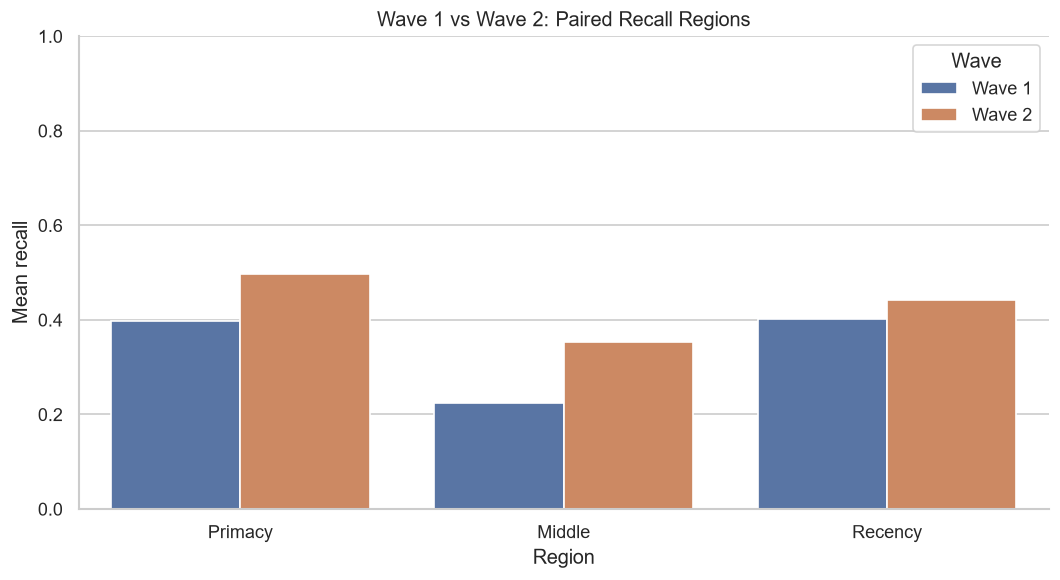

In [5]:
df = paired if paired is not None else longitudinal

regions = ["primacy", "middle", "recency"]
rows = []

for region in regions:
    w1 = get_col(
        df,
        f"w1_{region}_rate",
        f"{region}_rate_w1",
        f"wave1_{region}_rate"
    )

    w2 = get_col(
        df,
        f"w2_{region}_rate",
        f"{region}_rate_w2",
        f"wave2_{region}_rate"
    )

    if w1 and w2:
        valid = df[[w1, w2]].dropna()

        rows.append({
            "Region": region.title(),
            "Wave 1": valid[w1].mean(),
            "Wave 2": valid[w2].mean(),
            "Paired N": len(valid)
        })

if rows:
    wave_summary = pd.DataFrame(rows)
    display(wave_summary)

    plot_df = wave_summary.melt(
        id_vars=["Region", "Paired N"],
        value_vars=["Wave 1", "Wave 2"],
        var_name="Wave",
        value_name="Mean recall"
    )

    fig, ax = plt.subplots(figsize=(9, 5))

    sns.barplot(
        data=plot_df,
        x="Region",
        y="Mean recall",
        hue="Wave",
        ax=ax
    )

    ax.set_title("Wave 1 vs Wave 2: Paired Recall Regions")
    ax.set_ylim(0, 1)

    save_figure("07_longitudinal_region_changes")
else:
    print("Wave-specific region columns not found.")

In [6]:
if spc_changes is not None:
    print("Paired SPC changes")
    display(spc_changes)

if education_changes is not None:
    print("SPC changes by education")
    display(education_changes)

Paired SPC changes


,prim_key,primacy_rate_w1,primacy_rate_w2,delta_primacy_rate,middle_rate_w1,middle_rate_w2,delta_middle_rate,recency_rate_w1,recency_rate_w2,delta_recency_rate,education_level,age_baseline
0,BBBTW,0.666667,0.333333,-0.333333,0.00,0.25,0.25,0.000000,0.666667,0.666667,1.0,64.0
1,BBQMB,0.666667,0.666667,0.000000,0.00,0.50,0.50,0.333333,0.333333,0.000000,2.0,76.0
2,BBSPW,0.666667,0.666667,0.000000,0.25,0.50,0.25,0.333333,0.333333,0.000000,3.0,60.0
3,BBVOD,0.666667,0.666667,0.000000,0.75,0.00,-0.75,0.666667,1.000000,0.333333,1.0,51.0
4,BBXZT,0.000000,1.000000,1.000000,0.25,0.00,-0.25,0.000000,0.000000,0.000000,1.0,63.0
...,...,...,...,...,...,...,...,...,...,...,...,...
500,LVQQZ,0.333333,0.666667,0.333333,0.00,0.50,0.50,0.333333,0.666667,0.333333,1.0,79.0
501,LWBQP,0.666667,0.333333,-0.333333,0.00,0.75,0.75,1.000000,0.666667,-0.333333,4.0,49.0
502,LWJGH,0.333333,0.000000,-0.333333,0.00,0.25,0.25,0.000000,0.333333,0.333333,1.0,71.0
503,LZMCR,0.333333,0.666667,0.333333,0.25,0.25,0.00,0.333333,0.666667,0.333333,2.0,52.0


SPC changes by education


,Unnamed: 0,delta_primacy_rate,delta_primacy_rate.1,delta_primacy_rate.2,delta_middle_rate,delta_middle_rate.1,delta_middle_rate.2,delta_recency_rate,delta_recency_rate.1,delta_recency_rate.2
0,NaN,count,mean,std,count,mean,std,count,mean,std
1,education_level,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.0,274,0.12165450121654499,0.36173487011010713,274,0.11313868613138686,0.3010524927754727,274,0.048661800486618,0.3448325340998297
3,2.0,171,0.08187134502923976,0.35945147983708337,171,0.14181286549707603,0.31737469052595624,171,0.054580896686159834,0.3555491055486515
4,3.0,35,0.07619047619047618,0.3799356179181395,35,0.06428571428571428,0.3705265388152198,35,0.01904761904761905,0.2908501977565324
5,4.0,25,0.04,0.38873012632302006,25,0.32,0.25535922410074274,25,-0.09333333333333332,0.5315943872846971
